# Cuándo el motor supera a una regresión: el riesgo exacto de CrusherBayes dados sus escalares, la planta virtual que lo prueba y el techo de información de la base de capacidad

**Pregunta:** ¿En qué condiciones predice CrusherBayes, la calibración del motor con una discrepancia estructural, un muestreo mejor que una regresión empírica sobre los mismos regresores, cuánto de eso lo deciden la curvatura propia del motor, la escala de la discrepancia y el diseño de los muestreos, y qué no pueden decir nunca diez muestreos sobre los escalares del motor?

- **Nivel:** 4, el método propuesto por el producto
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 75 minutos

## Objetivos

Al terminar este notebook usted puede:

- escribir la media y la varianza predictivas de CrusherBayes con escalares fijos, mostrar que la media es una regresión de cresta hacia el mejor plano del motor más el desvío del motor respecto de ese plano, y comprobar ambas formas con la función predictiva del propio producto;
- medir el desvío del motor respecto de un plano en un conjunto de muestreos, y decir por qué es cero para el tonelaje y unos pocos kilowatts para la potencia;
- calcular el riesgo exacto del predictor en una planta virtual, hallar la parte de curvatura con la que el motor deja de ayudar y confirmar la fórmula con un Monte Carlo;
- leer el estudio de capacidad: cuándo paga un motor de la forma correcta, cuándo cuesta uno de forma equivocada, y por qué un motor afín es solo un objetivo de contracción;
- hallar la escala de la discrepancia que minimiza el riesgo de diseño fijo, ver por qué el valor del producto queda a su lado y leer el óptimo con retención del estudio versionado;
- calcular el techo de información de la base de capacidad con los diez muestreos y decir qué no puede cambiar ningún número de muestreos a esta velocidad en el mismo rango de abertura;
- nombrar dónde la forma cerrada deja de describir el método, y aplicar los diagnósticos a una tabla propia.

## Preparación

Numpy y matplotlib; el módulo de CrusherBayes y el arnés del estudio del manuscrito (`manuscripts/crusherbayes-theory/sim`) se importan por su ruta. El notebook no corre el muestreador.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el módulo de CrusherBayes (su función predictiva, sus a priori y el motor) y los módulos del arnés para las plantas virtuales, los conjuntos de puntos de operación y el riesgo en forma cerrada.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline y el arnés del estudio se importan
# por su ruta
ROOT = Path("../../..").resolve()
STUDY = ROOT / "manuscripts/crusherbayes-theory"
sys.path.insert(0, str(ROOT / "data-pipeline"))
sys.path.insert(0, str(STUDY / "sim"))
# Solo funciones públicas: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb
from pipeline.hp500 import loo
from pipeline.model.crusher import capacity, evaluate
from pipeline.model.crusher.envelope import check_envelope
from pipeline.model.crusher.hp500 import operating_from_survey
import engines
import inputs
import plants
import pools
import predictors
import theory
from heldout_uq import ROCHA, WI_BLEND, rocha_shape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos de HP500. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las filas se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`; `data/derived/hp500/crusherbayes.json`, con el lector del arnés, para los escalares ajustados a los diez muestreos, la discrepancia ajustada y las escalas de ruido; y del estudio del manuscrito de teoría de CrusherBayes, bajo `manuscripts/crusherbayes-theory/data/`, los resúmenes `pilot.json`, `identifiability.json`, `tau_coverage.json` y las celdas de ruta exacta `exact/Ccap_*.json` y `exact/V1_*.json`. Esas celdas vienen de simulaciones de 1.900 réplicas con 200 puntos de prueba cada una, horneadas fuera de línea; un notebook nunca las vuelve a correr, y un número leído de ellas se llama versionado en el texto. Todo otro número se calcula aquí, sobre 300 puntos de operación como máximo.

La celda lee los muestreos, el ajuste a los diez y los resúmenes por clave; un archivo ausente la detiene con su ruta, y nada lo reemplaza.

In [2]:
# Los diez muestreos, el ajuste a los diez que el producto distribuye (los escalares, la discrepancia y las
# escalas de ruido) y los resúmenes del estudio, leídos por clave
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
y = {"tph": np.array([s.feed_tph for s in surveys]), "kW": np.array([s.power_kw for s in surveys])}
fit = inputs.load_fit()


def read_summary(relative):
    # Un resumen ausente detiene la corrida con su ruta; no hay número de reemplazo
    path = STUDY / "data" / relative
    if not path.is_file():
        raise FileNotFoundError("missing summary: " + path.relative_to(ROOT).as_posix())
    return json.loads(path.read_text(encoding="utf-8"))


NS = (10, 20, 40, 80, 160)
SIZES = [("real", 10)] + [(d, n) for d in ("surveys", "wide", "extrapolation") for n in NS]
ccap = {(k, d, n): read_summary(f"exact/Ccap_{k}-{d}-n{n}.json") for k in engines.ANALYTIC for d, n in SIZES}
v1_cells = {(a, d): read_summary(f"exact/V1_{a}_k0-{d}-n160.json") for a in ("a1", "a2") for d in ("surveys",)}
v1_cells[("a1_k2", "surveys")] = read_summary("exact/V1_a1_k2-surveys-n160.json")
v1_cells[("a1_k2", "extrapolation")] = read_summary("exact/V1_a1_k2-extrapolation-n160.json")
v1_cells[("a1", "extrapolation")] = read_summary("exact/V1_a1_k0-extrapolation-n160.json")
pilot = read_summary("pilot.json")
ident = read_summary("identifiability.json")
tau_cov = read_summary("tau_coverage.json")
reps = ccap[("rocha", "surveys", 160)]["reps"]
text = ('muestreos: {} | celdas de capacidad leídas: {} | réplicas por celda: {} | '
        'sigma del estudio {:.3f} kW y {:.1f} t/h')
print(text.format(len(surveys), len(ccap), reps, ident["sigma"]["kW"], ident["sigma"]["tph"]))

muestreos: 10 | celdas de capacidad leídas: 48 | réplicas por celda: 1900 | sigma del estudio 38.812 kW y 145.2 t/h


## Método

### El predictivo de CrusherBayes dados sus escalares

**Hipótesis y veredictos.** El estudio de teoría enuncia, antes de correrlo, tres afirmaciones sobre el método propuesto. Con los escalares dados, CrusherBayes supera a mínimos cuadrados sobre los mismos regresores si y solo si el término de curvatura de (7) más abajo es positivo. En el tonelaje, donde la capacidad del motor es afín, la ganancia es cero salvo un efecto de contracción, y con una ley de capacidad curva como la de la planta crece con el ancho de la ventana y es mayor en extrapolación. Muestreos a velocidad fija en el mismo rango de abertura no pueden estrechar la base de capacidad más allá de un techo, y muestreos a velocidad variada la estrecharían más que duplicar su número. Los veredictos, como los registra el manuscrito y como los miden las celdas de abajo: la primera afirmación se cumplió; la segunda se cumplió para el motor de la forma propia de la planta y falló para el motor con la mitad de sus exponentes, que perdió en la ventana ancha y en extrapolación; el techo se cumplió y la cláusula de la velocidad falló.

CrusherBayes escribe cada salida $t$ de un muestreo, el tonelaje o la potencia, como el motor con ocho escalares $\boldsymbol\theta$ más un plano de discrepancia más ruido, $y = f_t(\boldsymbol\theta;\mathbf x) + \tilde{\mathbf z}^{\top}\mathbf d + \varepsilon$, con los regresores $\tilde{\mathbf z} = (1, z_c, z_f)$ (la abertura y el tamaño de alimentación estandarizados), un a priori $\mathbf d \sim N(\mathbf 0, \tau_t^2\mathbf I)$ y ruido de desviación estándar $\sigma_t$ (Kennedy y O'Hagan, 2001). El método completo muestrea $\boldsymbol\theta$ y $\sigma_t$. **Este notebook los fija**, porque con los escalares dados el predictivo es exacto en forma cerrada, y la forma cerrada es lo que analiza la teoría. Sea $\mathbf Z$ los regresores de los $n$ muestreos de entrenamiento, $\mathbf G = \mathbf Z^{\top}\mathbf Z$, $\lambda_t = \sigma_t^2/\tau_t^2$, y $\mathbf f_t$ el motor en los muestreos de entrenamiento. El predictivo de un muestreo retenido con regresores $\tilde{\mathbf z}_h$ es normal, con

$$\hat y_t(\mathbf x_h) = f_t(\boldsymbol\theta;\mathbf x_h) + \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda_t\mathbf I)^{-1}\mathbf Z^{\top}(\mathbf y_t - \mathbf f_t) \tag{1}$$

$$s_t^2(\mathbf x_h) = \sigma_t^2\bigl(1 + \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda_t\mathbf I)^{-1}\tilde{\mathbf z}_h\bigr) \tag{2}$$

es decir, el motor corregido por un ajuste de cresta de sus propios residuos. La celda retiene el muestreo 5, fija los escalares en sus valores de fábrica con el ruido en las medianas a priori, calcula (1) y (2) con numpy, y pone el resultado junto a `_Problem.predict` del producto, que condiciona la discrepancia exactamente como lo hace el muestreador en una muestra a posteriori, y junto al predictor en forma cerrada del arnés.

In [3]:
# Se retiene el muestreo 5 y se ajustan los otros nueve con los escalares del motor fijos en sus valores de
# fábrica
held = 4
train = np.array([i for i in range(10) if i != held])
theta = cb.nominal_theta()
problem = cb._Problem(css, f80, y, train)
via_product = problem.predict(theta, held)
# El motor con esos escalares en cada muestreo, y los regresores de la discrepancia en la estandarización del
# entrenamiento
shipped = [evaluate(op, cb.scalars_of(theta)) for op in problem.ops]
engine_pair = (np.array([r.throughput_tph for r in shipped]), np.array([r.power_kw for r in shipped]))
f_all = dict(zip(cb.TARGETS, engine_pair))
Z = cb.design(css[train], f80[train], problem.mu, problem.sd)
z_h = cb.design(css[[held]], f80[[held]], problem.mu, problem.sd)[0]
closed = {}
print(""
      "objetivo  lambda  media cerrada  media del producto  var cerrada  var del producto  media arnés  mayor brecha")
row_format = "{:6s} {:7.3f} {:12.4f} {:13.4f} {:11.3f} {:12.3f} {:12.4f} {:11.1e}"
for k, t in enumerate(cb.TARGETS):
    sigma, tau = math.exp(theta[cb.N_ENGINE + k]), cb.DISCREPANCY_SD[t]
    lam = sigma**2 / tau**2
    # Ecuaciones (1) y (2): el motor más el ajuste de cresta de sus residuos, y la varianza del predictivo
    A = np.linalg.inv(Z.T @ Z + lam * np.eye(3))
    mean = f_all[t][held] + z_h @ A @ Z.T @ (y[t][train] - f_all[t][train])
    var = sigma**2 * (1 + z_h @ A @ z_h)
    harness = predictors.cb_fixed(Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]], sigma, tau)
    gap = max(abs(mean - via_product[t][0]), abs(var - via_product[t][1]), abs(mean - harness[0][0]))
    closed[t] = mean
    print(row_format.format(t, lam, mean, via_product[t][0], var, via_product[t][1], harness[0][0], gap))
    factor = loo.band_factor(0.8)
    low, high = mean - factor * math.sqrt(var), mean + factor * math.sqrt(var)
    print(f"{'':6s} intervalo de 80%, factor {factor} {low:.1f} a {high:.1f}, medido {y[t][held]:.1f}")

objetivo  lambda  media cerrada  media del producto  var cerrada  var del producto  media arnés  mayor brecha
tph      0.184    1118.1651     1118.1651    4504.619     4504.619    1118.1651     4.8e-11
       intervalo de 80%, factor 1.2816 1032.1 a 1204.2, medido 1124.0
kW       0.174     289.8989      289.8989     281.609      281.609     289.8989     2.5e-12
       intervalo de 80%, factor 1.2816 268.4 a 311.4, medido 325.0


Los tres cálculos coinciden: la mayor brecha entre la forma cerrada, la función del producto y el arnés es 4,8e-11 en el tonelaje y 2,5e-12 en la potencia, que es redondeo. Las ecuaciones (1) y (2) son entonces lo que el producto evalúa en cada muestra a posteriori, con la varianza predictiva 4504,619 (t/h)$^2$ para el tonelaje y 281,609 kW$^2$ para la potencia con estas escalas de ruido. La contracción $\lambda$ es 0,184 y 0,174, pequeña frente a los valores propios de $\mathbf G$, que con nueve muestreos son del orden de nueve. El intervalo de 80 por ciento, con el factor 1,2816 de `loo.band_factor`, es 1032,1 a 1204,2 t/h para el tonelaje y cubre el 1124,0 medido; para la potencia es 268,4 a 311,4 kW y no cubre el 325,0 medido, porque el ruido está fijo en su mediana a priori de 15 kW mientras el residuo de la propia planta ronda los 39 kW (la escala de ruido ajustada es 38,812 kW): el muestreador la aprende. El predictivo del muestreador es una mezcla de tales normales sobre el a posteriori de los escalares; el resto del notebook estudia un componente de la mezcla, porque el riesgo de un componente es exacto.

### La forma de cresta: mínimos cuadrados más el desvío del motor respecto de su plano

Se proyecta el motor sobre los regresores de los muestreos de entrenamiento: $\mathbf b = \mathbf G^{-1}\mathbf Z^{\top}\mathbf f$ es el mejor plano del motor, y $\mathbf e = \mathbf f - \mathbf Z\mathbf b$ es lo que ningún plano en la abertura y el tamaño de alimentación representa. En el muestreo retenido se escribe $e_h = f(\mathbf x_h) - \tilde{\mathbf z}_h^{\top}\mathbf b$. El álgebra sobre (1) da la identidad de cresta del manuscrito,

$$\hat y_t(\mathbf x_h) = \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda\mathbf I)^{-1}\bigl(\mathbf Z^{\top}\mathbf y + \lambda\,\mathbf b\bigr) + e_h \tag{3}$$

una regresión de cresta del muestreo sobre los regresores que contrae hacia el plano $\mathbf b$ del motor en vez de hacia cero, más el desvío del motor respecto de ese plano en el muestreo retenido. Dos consecuencias sostienen el resto del notebook. Con $\lambda = 0$ el predictor es mínimos cuadrados sobre los regresores más $e_h$: el motor aporta solo su desvío respecto de un plano. Con $\lambda > 0$ el motor aporta además su plano, como objetivo de contracción. La celda calcula ambas formas para ambas salidas.

In [4]:
# El mejor plano b del motor sobre los nueve muestreos de entrenamiento, su desvío e_h en el muestreo retenido
# y las dos formas de la media
print(""
      "objetivo  e_h  plano en h  media cerrada  forma cresta  lambda = 0: MCO + e_h  predictor lambda ~ 0")
for k, t in enumerate(cb.TARGETS):
    sigma, tau = math.exp(theta[cb.N_ENGINE + k]), cb.DISCREPANCY_SD[t]
    b = np.linalg.lstsq(Z, f_all[t][train], rcond=None)[0]
    e_h = f_all[t][held] - z_h @ b
    # Cresta hacia el plano del motor, más el desvío del motor respecto de él en el muestreo retenido
    lam = sigma**2 / tau**2
    ridge = theory.ridge_identity_mean(Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]], lam)[0]
    # Sin contracción: mínimos cuadrados sobre los regresores más e_h, y el predictor con una escala a priori
    # de un millón
    plane_ls = z_h @ np.linalg.lstsq(Z, y[t][train], rcond=None)[0]
    args = (Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]])
    wide_prior = predictors.cb_fixed(*args, sigma, 1e6)[0][0]
    row = (e_h, z_h @ b, closed[t], ridge, plane_ls + e_h, wide_prior)
    print(f"{t:6s} {row[0]:8.3f} {row[1]:14.3f} {row[2]:12.4f} {row[3]:11.4f} {row[4]:22.4f} {row[5]:20.4f}")

objetivo  e_h  plano en h  media cerrada  forma cresta  lambda = 0: MCO + e_h  predictor lambda ~ 0
tph       0.000       1106.711    1118.1651   1118.1651              1117.0038            1117.0038
kW        5.653        409.533     289.8989    289.8989               288.1213             288.1213


La forma de cresta (3) da 1118,1651 para el tonelaje y 289,8989 para la potencia, los valores de la forma cerrada de (1) a cuatro decimales. Con la escala a priori elevada a un millón, de modo que $\lambda$ es prácticamente cero, el predictor da 1117,0038 y 288,1213, y esos son mínimos cuadrados sobre los nueve muestreos más $e_h$: las dos últimas columnas coinciden. El desvío $e_h$ es 0,000 t/h para el tonelaje y 5,653 kW para la potencia. En este muestreo la curvatura del motor mueve la predicción de potencia en 5,653 kW y la de tonelaje en nada, y la contracción hacia el plano del motor es lo que sube el tonelaje de 1117,0038 a 1118,1651 y la potencia de 288,1213 a 289,8989.

### La función de capacidad es afín en la abertura

El tonelaje del motor en el carril HP500 es la función de capacidad del producto, $Q = Q_{\mathrm{ref}}\,\frac{c + t/2}{38}\,s\,e^{1-s}$, con $t$ el recorrido en milímetros y $s$ la velocidad sobre su óptimo, así que con el recorrido fijo de 34 mm del carril y su velocidad esto es la recta $Q_{\mathrm{ref}}(c + 17)/38$ en la abertura $c$, y no depende del tamaño de alimentación. La celda llama a `capacity.throughput` sobre las aberturas de la envolvente calibrada con la base de capacidad ajustada, ajusta una recta al resultado e informa cuánto se aparta la función de ella.

In [5]:
# La función de capacidad del propio motor con la base de capacidad ajustada, sobre las aberturas de la
# envolvente calibrada con el recorrido y la velocidad del carril
q_fit = cb.scalars_of(np.concatenate([fit.theta0, [0.0, 0.0]])).q_ref_tph
op0 = problem.ops[0]
settings = np.linspace(38.0, 55.0, 18)
capacity_t_h = np.array([
    capacity.throughput(op0.machine, c, op0.throw_mm, op0.speed_rpm, True, hp500_q_ref=q_fit) for c in settings
])
# Una recta que lo atraviesa, y la misma recta escrita como Q_ref (c + 17) / 38
slope, intercept = np.polyfit(settings, capacity_t_h, 1)
miss = np.abs(capacity_t_h - (slope * settings + intercept)).max() / capacity_t_h.mean()
text = "recorrido {} mm, velocidad {} rpm, Q_ref ajustado {:.2f} t/h"
print(text.format(op0.throw_mm, op0.speed_rpm, q_fit))
text = "pendiente sobre Q_ref/38: {:.4f} | intercepto sobre 17 Q_ref/38: {:.4f}"
print(text.format(slope * 38 / q_fit, intercept * 38 / (17 * q_fit)))
print("mayor brecha a la recta, relativa: bajo 1e-9 es {}".format(miss < 1e-9))

recorrido 34 mm, velocidad 360 rpm, Q_ref ajustado 646.35 t/h
pendiente sobre Q_ref/38: 1.0000 | intercepto sobre 17 Q_ref/38: 1.0000
mayor brecha a la recta, relativa: bajo 1e-9 es True


La base de capacidad ajustada a los diez muestreos es 646,35 t/h. La recta que atraviesa la función tiene una pendiente de 1,0000 veces $Q_{\mathrm{ref}}/38$ y un intercepto de 1,0000 veces $17\,Q_{\mathrm{ref}}/38$, y la mayor brecha entre la función y la recta es menor que 1e-9 de su nivel: la capacidad es exactamente $Q_{\mathrm{ref}}(c + 17)/38$ con recorrido de 34 mm y velocidad de 360 rpm. Una función de la abertura sola está en el espacio de $(1, c, f_{80})$ sea cual sea el valor de $Q_{\mathrm{ref}}$, que es la razón por la que la celda siguiente no halla desvío para el tonelaje. No dice que el tonelaje de la planta sea afín, solo que el del motor lo es.

### El desvío del motor respecto de un plano en los diez muestreos

En el carril HP500 a su velocidad fija el tonelaje del motor es $Q_{\mathrm{ref}}(c + 17)/38$, con $c$ la abertura en milímetros: una función afín de la abertura sean cuales sean los ocho escalares, así que su desvío respecto de cualquier plano en $(1, c, f_{80})$ es cero. La potencia no es afín, porque multiplica la capacidad por una energía específica que depende de los tamaños de alimentación y de producto. Con los diez muestreos como conjunto de entrenamiento, el desvío del motor y el residuo medido de un plano de mínimos cuadrados son

$$\mathbf e = \mathbf f - \mathbf Z(\mathbf Z^{\top}\mathbf Z)^{-1}\mathbf Z^{\top}\mathbf f, \qquad \hat{\mathbf r} = \mathbf y - \mathbf Z(\mathbf Z^{\top}\mathbf Z)^{-1}\mathbf Z^{\top}\mathbf y \tag{4}$$

El residuo medido $\hat{\mathbf r}$ contiene la curvatura propia de la planta $\mathbf r$ más la parte del ruido que el plano no puede absorber, así que su raíz cuadrática media sobrestima la curvatura. La celda calcula ambos con los escalares ajustados (las medias a posteriori del documento del producto) y con los de fábrica, para ambas salidas, con la correlación de $\mathbf e$ y $\hat{\mathbf r}$, que el piloto del estudio también informa para el modelo base calibrado.

In [6]:
# El motor con los escalares ajustados (las medias a posteriori que distribuye el producto) y con los de
# fábrica, en los diez muestreos
Z10 = cb.design(css, f80, np.array([css.mean(), f80.mean()]), np.array([css.std(), f80.std()]))
fitted_scalars = cb.scalars_of(np.concatenate([fit.theta0, [0.0, 0.0]]))
fitted = [evaluate(op, fitted_scalars) for op in problem.ops]
fitted_pair = (np.array([r.throughput_tph for r in fitted]), np.array([r.power_kw for r in fitted]))
engine_at = {"fitted": fitted_pair, "shipped": engine_pair}
plane = {}
print(""
      "escalares  objetivo  rms de e  mayor |e| sobre el nivel  rms de r-hat  correlación de e y r-hat")
for label, pair in engine_at.items():
    for t, f in zip(cb.TARGETS, pair):
        # Ecuación (4): la parte del motor y de la medición que ningún plano en (1, CSS, f80) representa
        e = f - Z10 @ np.linalg.lstsq(Z10, f, rcond=None)[0]
        r_hat = y[t] - Z10 @ np.linalg.lstsq(Z10, y[t], rcond=None)[0]
        plane[(label, t)] = (e, r_hat)
        relative = np.abs(e).max() / np.abs(f).mean()
        rho = f"{np.corrcoef(e, r_hat)[0, 1]:.3f}" if relative > 1e-9 else "indefinida"
        flag = "bajo 1e-9" if relative < 1e-9 else f"{relative:.3f}"
        e_rms, r_rms = np.sqrt(np.mean(e**2)), np.sqrt(np.mean(r_hat**2))
        print(f"{label:8s} {t:6s} {e_rms:9.3f} {flag:>22s} {r_rms:12.3f} {rho:>24s}")
text = "piloto del estudio (motor del modelo base calibrado): sd del desvío de potencia {} kW, correlación {}"
print(text.format(pilot["kW"]["engine_departure_sd"], pilot["kW"]["corr"]))

escalares  objetivo  rms de e  mayor |e| sobre el nivel  rms de r-hat  correlación de e y r-hat
fitted   tph        0.000              bajo 1e-9      119.646               indefinida
fitted   kW         6.132                  0.047       33.182                    0.463
shipped  tph        0.000              bajo 1e-9      119.646               indefinida
shipped  kW         5.633                  0.033       33.182                    0.450
piloto del estudio (motor del modelo base calibrado): sd del desvío de potencia 5.638 kW, correlación 0.452


La figura dibuja los dos desvíos muestreo a muestreo, el residuo medido como barras grises y el desvío del motor como barras negras, el tonelaje a la izquierda y la potencia a la derecha, con los escalares ajustados.

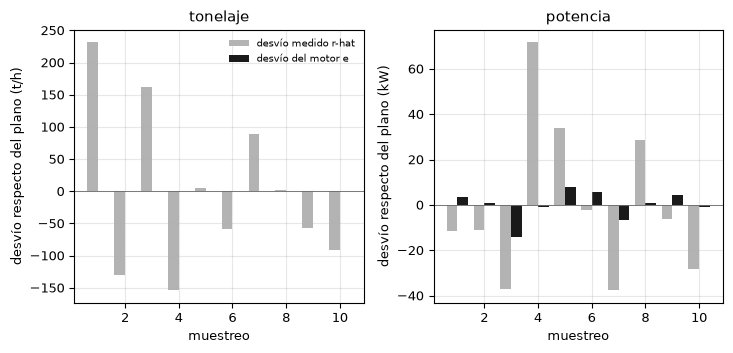

In [7]:
# Figura 1: el desvío de la planta respecto de su plano (barras) frente al del motor (puntos), muestreo a
# muestreo, tonelaje a la izquierda y potencia a la derecha
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.6))
x = np.arange(1, 11)
for ax, t, unit in zip(axes, cb.TARGETS, ("t/h", "kW")):
    e, r_hat = plane[("fitted", t)]
    ax.bar(x - 0.2, r_hat, width=0.4, color="0.7", label="desvío medido r-hat")
    ax.bar(x + 0.2, e, width=0.4, color="0.1", label="desvío del motor e")
    ax.axhline(0, color="0.4", lw=0.6)
    ax.set_xlabel("muestreo")
    ax.set_ylabel(f"desvío respecto del plano ({unit})")
    ax.set_title("tonelaje" if t == "tph" else "potencia")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

Para el tonelaje el desvío del motor es menor que 1e-9 de su nivel con ambos conjuntos de escalares, así que las barras negras del panel izquierdo no existen, mientras el residuo medido tiene una raíz cuadrática media de 119,646 t/h: el motor no tiene curvatura que ofrecer a la predicción de tonelaje, solo un plano. Para la potencia el motor se desvía de un plano en 6,132 kW de raíz cuadrática media con los escalares ajustados y 5,633 kW con los de fábrica, frente a un residuo medido de 33,182 kW, y ambos están correlacionados positivamente (0,463 y 0,450; el piloto del estudio, con el motor del modelo base calibrado, da 0,452). La figura no muestra si esa correlación es más que azar: descansa en diez puntos, y la última sección le pone un intervalo. También oculta que las barras grises incluyen ruido que ningún motor podría explicar.

## Comparación

### El riesgo exacto del predictor en una planta virtual

Que la curvatura del motor ayude depende de la función media de la planta, que ningún conjunto finito de muestreos revela. El estudio construye entonces plantas virtuales cuya función media es conocida, simula muestreos de ellas y compara el predictor con mínimos cuadrados. Con los escalares fijos el riesgo es exacto. Para un diseño de entrenamiento con regresores $\mathbf Z$, ruido $\sigma$, la media de la planta $\boldsymbol\mu$ proyectada como en (4) en $\boldsymbol\beta$ y $\mathbf r$, el motor en $\mathbf b$ y $\mathbf e$, $\boldsymbol\delta = \mathbf b - \boldsymbol\beta$ y $\mathbf A_\lambda = (\mathbf G + \lambda\mathbf I)^{-1}$, el error cuadrático esperado en un punto retenido, sobre el ruido de entrenamiento y de prueba, es

$$R_\lambda(\mathbf x_h) = \bigl(r_h - e_h - \lambda\,\tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\boldsymbol\delta\bigr)^2 + \sigma^2\,\tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\mathbf G\mathbf A_\lambda\tilde{\mathbf z}_h + \sigma^2 \tag{5}$$

$$R_{\mathrm{LS}}(\mathbf x_h) = r_h^2 + \sigma^2\,\tilde{\mathbf z}_h^{\top}\mathbf G^{-1}\tilde{\mathbf z}_h + \sigma^2 \tag{6}$$

Nada supone que la planta sea el motor, que el a priori sea correcto ni que el ruido del modelo sea el de la planta. Con $\lambda = 0$ la diferencia de ambos se reduce a $e_h(2 r_h - e_h)$, así que sobre los puntos retenidos, con $\rho$ la correlación de $e$ con $r$ y $\kappa = \lVert e\rVert/\lVert r\rVert$,

$$\mathbb E\,[R_{\mathrm{LS}} - R_0] = 2\langle e, r\rangle - \lVert e\rVert^2 = \lVert r\rVert^2\,(2\rho\kappa - \kappa^2) \tag{7}$$

que es positiva si y solo si $0 < \kappa < 2\rho$. El motor ayuda únicamente a través de una curvatura que apunta como la de la planta y no es más del doble de grande; una de signo contrario siempre pierde. El ruido no entra en (7): la ganancia es un término de sesgo, y no decae con el número de muestreos.

Las plantas son la familia $\boldsymbol\mu_\alpha = \mathbf z_{\mathrm{ref}}^{\top}(\mathbf b_0 + \mathbf d_0) + \alpha\,e_0$: la planta ajustada a los diez muestreos con una parte $\alpha$ de la curvatura de potencia propia del motor $e_0$. Entonces $\alpha = 1$ es la planta ajustada, $\alpha = 0$ es una planta que es un plano, $\alpha = -1$ invierte la curvatura del motor, y (7) dice que la ganancia es $(2\alpha - 1)\lVert e_0\rVert^2$, con cambio de signo en $\alpha = 1/2$. La celda construye el conjunto de 300 puntos, evalúa el motor en él con los escalares ajustados y ajusta la familia.

In [8]:
# Un conjunto pequeño de 300 puntos de operación uniformes en la ventana de los muestreos (CSS 38 a 55 mm, f80
# 47 a 140 mm, 360 rpm) y el motor con los escalares ajustados en él
pool = pools.window_points("surveys", 300)
engine_pool = engines.product_eval(pool, fit.theta0, workers=1, jac=False)
f_pool = engine_pool["kW"]
mu_ref, sd_ref = inputs.reference_standardization()
z_ref = pools.design_matrix(pool, mu_ref, sd_ref)
# La familia de plantas V1(alpha): la planta ajustada con una parte alpha de la curvatura propia del motor en
# potencia e_0 (alpha = 1 es la planta ajustada)
basis = plants.V1Basis.fit(f_pool, z_ref)
sigma_kw, tau_kw = fit.sigma["kW"], cb.DISCREPANCY_SD["kW"]
lam_prod = sigma_kw**2 / tau_kw**2
text = "puntos {} | fallas del motor {} | rms de e_0 {:.3f} kW | sigma {:.3f} kW | sigma^2 {:.1f} kW^2 | lambda {:.4f}"
print(text.format(pool.shape[0], int((~engine_pool["ok"]).sum()), basis.rms_e0, sigma_kw, sigma_kw**2, lam_prod))

puntos 300 | fallas del motor 0 | rms de e_0 4.148 kW | sigma 38.812 kW | sigma^2 1506.4 kW^2 | lambda 1.1623


El conjunto tiene 300 puntos de operación uniformes en la ventana de los muestreos. La celda siguiente saca de él un diseño de entrenamiento de 100 puntos y 150 de prueba y evalúa, para cinco valores de $\alpha$, la diferencia de riesgo exacta de (5) y (6) con $\lambda = 0$ y con el $\lambda$ del producto, junto a las cantidades de alineación $\rho$ y $\kappa$ y la expresión (7) del corolario.

In [9]:
# Un diseño de entrenamiento de 100 puntos y 150 de prueba del conjunto; el riesgo exacto de las ecuaciones
# (5) y (6) para cada alpha
rng = np.random.default_rng(20261119)
train_i, test_i, _ = pools.draw_design(rng, "surveys", 100, 150, pool, np.arange(300))
m_tr, s_tr = pools.standardization(pool[train_i])
Z_tr = pools.design_matrix(pool[train_i], m_tr, s_tr)
Z_te = pools.design_matrix(pool[test_i], m_tr, s_tr)
plant_mean = {}
risk_table = {}
print("puntos de entrenamiento {} | puntos de prueba {}".format(train_i.size, test_i.size))
print(""
      "alpha  rho  kappa  2<e,r>-|e|^2  ganancia, lambda 0  ganancia, lambda del producto")
for alpha in (-1.0, 0.0, 0.5, 1.0, 2.0):
    mu = basis.mean(alpha, 0.0, f_pool, z_ref, fit.d0["kW"])
    plant_mean[alpha] = mu
    beta = np.linalg.lstsq(Z_tr, mu[train_i], rcond=None)[0]
    b = np.linalg.lstsq(Z_tr, f_pool[train_i], rcond=None)[0]
    r_h, e_h = mu[test_i] - Z_te @ beta, f_pool[test_i] - Z_te @ b
    args = (Z_tr, mu[train_i], f_pool[train_i], Z_te, mu[test_i], f_pool[test_i], sigma_kw)
    risk_ls = theory.expected_sq_error_ls(Z_tr, mu[train_i], Z_te, mu[test_i], sigma_kw)
    gain_zero = (risk_ls - theory.expected_sq_error(*args, 0.0)).mean()
    gain_prod = (risk_ls - theory.expected_sq_error(*args, lam_prod)).mean()
    # Una planta que es un plano no tiene curvatura, así que rho y kappa no existen
    has_r = np.sqrt(r_h @ r_h) > 1e-6 * np.sqrt(e_h @ e_h)
    rho = (e_h @ r_h) / np.sqrt((e_h @ e_h) * (r_h @ r_h)) if has_r else float("nan")
    kappa = np.sqrt((e_h @ e_h) / (r_h @ r_h)) if has_r else float("nan")
    risk_table[alpha] = (rho, kappa, gain_zero, gain_prod)
    shown_rk = f"{rho:6.3f} {kappa:6.3f}" if has_r else "  none   none"
    check = np.round(np.mean(e_h * (2 * r_h - e_h)), 3) + 0.0
    pair = (np.round(gain_zero, 3) + 0.0, np.round(gain_prod, 3) + 0.0)
    print(f"{alpha:5.1f} {shown_rk} {check:13.3f} {pair[0]:14.3f} {pair[1]:20.3f}")

puntos de entrenamiento 100 | puntos de prueba 150
alpha  rho  kappa  2<e,r>-|e|^2  ganancia, lambda 0  ganancia, lambda del producto
 -1.0 -1.000  1.000       -52.815        -52.815              -53.046
  0.0   none   none       -17.605        -17.605              -17.373
  0.5  1.000  2.000         0.000          0.000                0.479
  1.0  1.000  1.000        17.605         17.605               18.343
  2.0  1.000  0.500        52.815         52.815               54.104


La desviación del motor $e_0$ del conjunto tiene una raíz cuadrática media de 4,148 kW, y $\sigma^2$ es 1506,4 kW$^2$. La diferencia de riesgo exacta con $\lambda = 0$ es -52,815, -17,605, 0,000, 17,605 y 52,815 kW$^2$ para $\alpha = -1, 0, 0{,}5, 1, 2$: los valores $(2\alpha - 1)$ por 17,605, que es $\lVert e_0\rVert^2$, e iguales a $2\langle e,r\rangle - \lVert e\rVert^2$ del corolario en la columna anterior a tres decimales. El par $(\rho, \kappa)$ explica los signos. Con $\alpha = 0{,}5$ la correlación es 1,000 y $\kappa = 2,000$, el borde de $0 < \kappa < 2\rho$; con $\alpha = 2$, $\kappa = 0,500$ y el motor gana; con $\alpha = -1$, $\rho = -1,000$ y pierde. Con $\alpha = 0$ la planta es un plano, $r$ es cero, $\rho$ y $\kappa$ no existen (se imprimen como none) y el costo es todo $\lVert e\rVert^2$, 17,605 kW$^2$ de una curvatura que la planta no tiene. Con el $\lambda$ del producto, 1,1623, los valores se mueven una fracción de kilowatt al cuadrado: 0,479 en vez de 0,000 en el cruce, 18,343 en vez de 17,605 con $\alpha = 1$.

Una fórmula vale lo que su acuerdo con lo que describe. La celda simula 400 réplicas sobre el mismo diseño: ruido nuevo en los 100 muestreos de entrenamiento y los 150 de prueba, el predictor de (1) con la escala de discrepancia del producto y mínimos cuadrados, y la diferencia pareada de sus errores cuadráticos en los muestreos de prueba, con su semiancho de 95 por ciento. Luego lee la grilla versionada del estudio e informa el mayor puntaje $z$ del error cuadrático simulado frente al exacto sobre todas sus celdas.

In [10]:
# Un Monte Carlo de 400 réplicas sobre el mismo diseño: ruido nuevo en los muestreos de entrenamiento y de
# prueba, la diferencia pareada de error cuadrático de mínimos cuadrados menos el predictor calibrado
REPS = 400
rng_mc = np.random.default_rng(20261120)
monte_carlo = {}
print("alpha  exacto (lambda del producto)  Monte Carlo  semiancho de 95%  exacto dentro del intervalo")
for alpha, mu in plant_mean.items():
    y_tr = mu[train_i][:, None] + sigma_kw * rng_mc.standard_normal((100, REPS))
    y_te = mu[test_i][:, None] + sigma_kw * rng_mc.standard_normal((150, REPS))
    mean_cb = predictors.cb_fixed(Z_tr, y_tr, f_pool[train_i], Z_te, f_pool[test_i], sigma_kw, tau_kw)[0]
    mean_ls = predictors.least_squares(Z_tr, y_tr, Z_te)[0]
    paired = ((y_te - mean_ls) ** 2 - (y_te - mean_cb) ** 2).mean(axis=0)
    half = 1.96 * paired.std(ddof=1) / np.sqrt(REPS)
    monte_carlo[alpha] = (paired.mean(), half)
    inside = abs(paired.mean() - risk_table[alpha][3]) <= half
    print(f"{alpha:5.1f} {risk_table[alpha][3]:24.3f} {paired.mean():12.3f} {half:15.3f} {str(inside):>26s}")
# La misma comparación en toda la grilla versionada: el mayor puntaje z absoluto del error cuadrático simulado
# frente al exacto
names = sorted(p.name for p in (STUDY / "data/exact").glob("*.json"))
z_all = [abs(z) for n in names for z in read_summary("exact/" + n)["theory_z"].values()]
print("grilla versionada: {} celdas, {} comparaciones, mayor |z| {:.2f}".format(len(names), len(z_all), max(z_all)))

alpha  exacto (lambda del producto)  Monte Carlo  semiancho de 95%  exacto dentro del intervalo
 -1.0                  -53.046      -52.675           2.818                       True
  0.0                  -17.373      -17.352           3.005                       True
  0.5                    0.479        0.292           2.839                       True
  1.0                   18.343       20.120           2.895                       True
  2.0                   54.104       52.051           2.969                       True
grilla versionada: 176 celdas, 832 comparaciones, mayor |z| 3.17


El Monte Carlo da -52,675, -17,352, 0,292, 20,120 y 52,051 kW$^2$ con semianchos de 2,8 a 3,0, y el valor exacto con el $\lambda$ del producto queda dentro del intervalo en los cinco valores de $\alpha$. La misma comparación en la grilla versionada, 176 celdas de 1900 réplicas cada una, tiene 832 comparaciones con un $|z|$ máximo de 3,17: unas pocas superan 3, como se espera entre tantas, y ninguna apunta a un error de la fórmula. Las ecuaciones (5) y (6) describen el predictor simulado con la exactitud de la simulación.

La figura grafica la ganancia exacta sobre mínimos cuadrados frente a $\alpha$ en una grilla fina con $\lambda = 0$ (la recta de (7)), los valores exactos con el $\lambda$ del producto (cuadrados abiertos) y el Monte Carlo (puntos con intervalos), con el cruce en $\alpha = 1/2$ punteado.

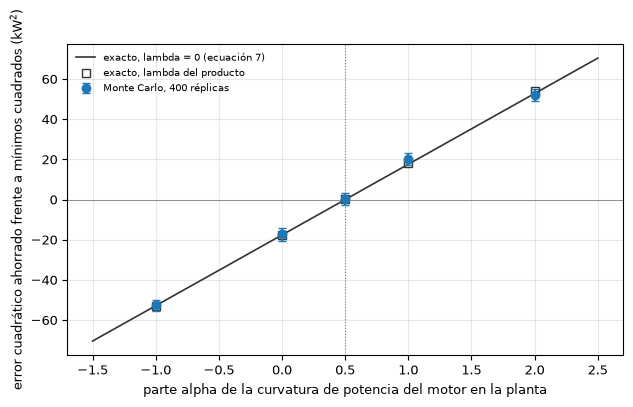

In [11]:
# Figura 2: la ganancia del predictor calibrado sobre mínimos cuadrados frente a alpha: la curva exacta con
# lambda 0, los valores exactos con el lambda del producto y el Monte Carlo con su intervalo de 95%
grid = np.linspace(-1.5, 2.5, 41)
curve = []
for alpha in grid:
    mu = basis.mean(alpha, 0.0, f_pool, z_ref, fit.d0["kW"])
    args = (Z_tr, mu[train_i], f_pool[train_i], Z_te, mu[test_i], f_pool[test_i], sigma_kw)
    risk_ls = theory.expected_sq_error_ls(Z_tr, mu[train_i], Z_te, mu[test_i], sigma_kw)
    curve.append((risk_ls - theory.expected_sq_error(*args, 0.0)).mean())
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(grid, curve, color="0.2", lw=1.2, label="exacto, lambda = 0 (ecuación 7)")
alphas = list(monte_carlo)
ax.plot(alphas, [risk_table[a][3] for a in alphas], "s", mfc="none", color="0.2", label="exacto, lambda del producto")
centre = [monte_carlo[a][0] for a in alphas]
spread = [monte_carlo[a][1] for a in alphas]
ax.errorbar(alphas, centre, yerr=spread, fmt="o", color="C0", capsize=3, label="Monte Carlo, 400 réplicas")
ax.axhline(0, color="0.5", lw=0.6)
ax.axvline(0.5, color="0.5", lw=0.8, ls=":")
ax.set_xlabel("parte alpha de la curvatura de potencia del motor en la planta")
ax.set_ylabel("error cuadrático ahorrado frente a mínimos cuadrados (kW$^2$)")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

La ganancia es una recta en $\alpha$ con pendiente $2\lVert e_0\rVert^2$ que cruza cero en un medio, y la simulación queda sobre ella. A la izquierda de la línea punteada la curvatura del motor es excesiva o está mal alineada con la planta y el predictor calibrado pierde frente a la regresión simple; a la derecha gana. La figura no muestra el tamaño de lo que está en juego: con $\alpha = 1$, la planta ajustada a los diez muestreos, la ganancia es 17,605 kW$^2$ frente a una varianza de ruido de 1506,4 kW$^2$, cerca de un uno por ciento. Incluso un motor perfectamente alineado puede quitar solo eso del error cuadrático, porque su curvatura es pequeña junto al ruido.

### La capacidad curva: un motor afín es solo un objetivo de contracción

El tonelaje del carril HP500 es el caso $e \equiv 0$. Entonces (5) menos (6) se reduce a

$$R_\lambda - R_{\mathrm{LS}} = \lambda^2 w_h^2 - 2\lambda\, r_h w_h - \sigma^2\,\tilde{\mathbf z}_h^{\top}\bigl(\mathbf G^{-1} - \mathbf A_\lambda\mathbf G\mathbf A_\lambda\bigr)\tilde{\mathbf z}_h, \qquad w_h = \tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\boldsymbol\delta \tag{8}$$

El último término es un ahorro de varianza, siempre positivo, que se achica al crecer el diseño; los dos primeros vienen del tirón de la contracción hacia el plano del motor y se anulan cuando los dos planos coinciden. Un motor afín no aporta entonces curvatura: CrusherBayes sobre el tonelaje es una regresión de cresta hacia el plano del motor, nada más. Una ley de capacidad curva en la abertura cambia eso. El estudio de capacidad usa como planta la capacidad publicada de Rocha et al. (2024), una ley de potencias en la abertura y el tamaño de alimentación, y tres motores: la capacidad afín de fábrica, la forma propia de la planta y la misma forma con los exponentes a la mitad. La celda mide la alineación de cada uno con la planta en dos ventanas, la de los muestreos y una más ancha (abertura de 25 a 70 mm), con la escala de cada motor fijada proyectando la planta sobre su forma, como en el oráculo del estudio (Tuo y Wu, 2015).

In [12]:
# Para los tres motores analíticos de capacidad frente a la capacidad publicada de Rocha et al. como planta:
# el desvío de la planta y del motor respecto de un plano, rho y kappa, en dos ventanas
print("ventana  motor  rms de r (t/h)  rms de e (t/h)  rho  kappa  ganancia 2<e,r>-|e|^2 como parte de |r|^2")
alignment = {}
for window in ("surveys", "wide"):
    pts = pools.window_points(window, 300)
    z = pools.design_matrix(pts, *pools.standardization(pts))
    plant = ROCHA["lam"] * rocha_shape(pts[:, 0], pts[:, 1], WI_BLEND)
    r = plant - z @ np.linalg.lstsq(z, plant, rcond=None)[0]
    for kind in engines.ANALYTIC:
        # La escala del motor es la proyección de mínimos cuadrados de la planta sobre su forma, como en el
        # oráculo del estudio
        shape = engines.analytic_shape(kind, pts)
        f = (plant @ shape) / (shape @ shape) * shape
        e = f - z @ np.linalg.lstsq(z, f, rcond=None)[0]
        e_rms, r_rms = np.sqrt(np.mean(e**2)), np.sqrt(np.mean(r**2))
        rho = f"{np.mean(e * r) / (e_rms * r_rms):6.3f}" if e_rms > 1e-6 * r_rms else "  none"
        share = np.round(np.mean(e * (2 * r - e)) / r_rms**2, 3) + 0.0
        alignment[(window, kind)] = share
        print(f"{window:8s} {kind:11s} {r_rms:9.2f} {e_rms:14.2f} {rho:>8s} {e_rms / r_rms:7.3f} {share:12.3f}")
    bound = 100 * (r_rms / ident["sigma"]["tph"]) ** 2
    print(window, "curvatura de la planta sobre el ruido, parte de la varianza: {:.1f} por ciento".format(bound))

ventana  motor  rms de r (t/h)  rms de e (t/h)  rho  kappa  ganancia 2<e,r>-|e|^2 como parte de |r|^2
surveys  affine          18.52           0.00     none   0.000        0.000
surveys  rocha           18.52          18.52    1.000   1.000        1.000
surveys  rocha_half      18.52           7.32    0.935   0.395        0.582
surveys curvatura de la planta sobre el ruido, parte de la varianza: 1.6 por ciento
wide     affine          19.37           0.00     none   0.000        0.000
wide     rocha           19.37          19.37    1.000   1.000        1.000
wide     rocha_half      19.37          11.30    0.116   0.583       -0.205
wide curvatura de la planta sobre el ruido, parte de la varianza: 1.8 por ciento


Frente a la capacidad publicada la planta se desvía de un plano en 18,52 t/h en la ventana de los muestreos y 19,37 t/h en la ancha. El motor afín no tiene desvío, así que $\rho$ no existe y la parte de (7) es 0,000. El motor de la forma propia de la planta tiene $\rho = 1,000$ y $\kappa = 1,000$, una parte de 1,000: el mejor caso de (7), donde la curvatura del motor es la de la planta. El motor con exponentes a la mitad en la ventana de los muestreos tiene $\rho = 0,935$ y $\kappa = 0,395$, una parte de 0,582, alineado y menor que el de la planta, así que gana. En la ventana ancha su desvío es 11,30 t/h pero de otra forma: $\rho = 0,116$, y $\kappa = 0,583$ supera a $2\rho$, así que (7) predice una pérdida, y la parte es -0,205.

La predicción de (7) es una afirmación sobre predictores simulados, así que la celda siguiente la contrasta con el estudio de capacidad versionado: para cada motor y ventana, el RMSE del predictor calibrado con la escala verdadera sobre el RMSE de mínimos cuadrados, con 160 muestreos de entrenamiento, con la diferencia pareada de error cuadrático y su error estándar, que es la evidencia que resuelve efectos de un uno por ciento.

In [13]:
# De los resúmenes de capacidad versionados con 160 muestreos: la diferencia pareada de error cuadrático con su error
# estándar, la razón de RMSE y la parte del RMSE que ahorra la forma propia de la planta
print("diferencia pareada de error cuadrático, calibrado menos mínimos cuadrados, n = 160 "
      "((t/h)^2; error estándar tras +-)")
for design in ("surveys", "wide", "extrapolation"):
    ratios, gains = {}, {}
    for kind in engines.ANALYTIC:
        cell = ccap[(kind, design, 160)]
        s, d = cell["predictors_summary"]["tph"], cell["paired"]["tph"]["cb_oracle"]["vs_ls"]
        ratios[kind] = s["cb_oracle"]["rmse"] / s["ls"]["rmse"]
        gains[kind] = -d["mean"]
        print(f"{design:14s} {kind:11s} {d['mean']:9.1f} +- {d['mcse']:.1f}   razón de RMSE {ratios[kind]:.4f}")
    saved = 100 * (1 - ratios["rocha"])
    print(design, "el motor de la forma de la planta ahorra {:.1f} por ciento del RMSE con n = 160".format(saved))
    share = 100 * gains["rocha"] / ident["sigma"]["tph"] ** 2
    print(design, "ganancia pareada de la forma de la planta, parte de sigma^2: {:.1f} por ciento".format(share))
for kind in engines.ANALYTIC:
    s = ccap[(kind, "real", 10)]["predictors_summary"]["tph"]
    print("diez muestreos, diseño real", kind, round(s["cb_oracle"]["rmse"] / s["ls"]["rmse"], 4))

diferencia pareada de error cuadrático, calibrado menos mínimos cuadrados, n = 160 ((t/h)^2; error estándar tras +-)
surveys        affine           -5.1 +- 0.5   razón de RMSE 0.9999
surveys        rocha          -360.4 +- 9.1   razón de RMSE 0.9917
surveys        rocha_half     -213.5 +- 3.6   razón de RMSE 0.9951
surveys el motor de la forma de la planta ahorra 0.8 por ciento del RMSE con n = 160
surveys ganancia pareada de la forma de la planta, parte de sigma^2: 1.7 por ciento
wide           affine           -4.4 +- 0.9   razón de RMSE 0.9999
wide           rocha          -429.1 +- 9.9   razón de RMSE 0.9902
wide           rocha_half       81.5 +- 5.7   razón de RMSE 1.0019
wide el motor de la forma de la planta ahorra 1.0 por ciento del RMSE con n = 160
wide ganancia pareada de la forma de la planta, parte de sigma^2: 2.0 por ciento
extrapolation  affine          -73.0 +- 2.3   razón de RMSE 0.9985
extrapolation  rocha         -1057.0 +- 31.6   razón de RMSE 0.9777
extrapolation 

La figura dibuja las razones de RMSE que resume la tabla, para cada motor y ventana frente al número de muestreos de entrenamiento, con los cinco tamaños en el eje.

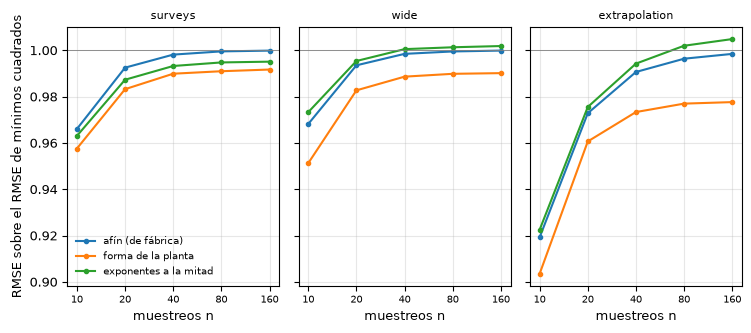

In [14]:
# Figura 3: de los resúmenes de capacidad versionados, el RMSE del predictor calibrado (escala verdadera) sobre el
# de mínimos cuadrados frente al número de muestreos, por motor y ventana
names = {"affine": "afín (de fábrica)", "rocha": "forma de la planta", "rocha_half": "exponentes a la mitad"}
fig, axes = plt.subplots(1, 3, figsize=(7.6, 3.4), sharey=True)
for ax, design in zip(axes, ("surveys", "wide", "extrapolation")):
    for kind in engines.ANALYTIC:
        ratio = [ccap[(kind, design, n)]["predictors_summary"]["tph"] for n in NS]
        ax.plot(NS, [s["cb_oracle"]["rmse"] / s["ls"]["rmse"] for s in ratio], marker="o", ms=3, label=names[kind])
    ax.axhline(1, color="0.5", lw=0.6)
    ax.set_xscale("log")
    ax.set_xticks(NS)
    ax.set_xticklabels(NS, fontsize=7)
    ax.minorticks_off()
    ax.set_xlabel("muestreos n")
    ax.set_title(design, fontsize=8)
axes[0].set_ylabel("RMSE sobre el RMSE de mínimos cuadrados")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

Cada curva queda bajo uno donde el motor ayuda. Con el motor afín la razón es 0,9757 en el diseño propio de los diez muestreos y 0,9999 con 160 muestreos en la ventana de los muestreos: la ganancia de contracción de (8) decae con el número de muestreos, como lo precisa la sección siguiente. El motor de la forma propia de la planta se mantiene bajo uno con 160 muestreos, 0,9917 en la ventana de los muestreos, 0,9902 en la ancha y 0,9777 en extrapolación, una ganancia que persiste y crece con la distancia de los puntos de prueba a la ventana de entrenamiento. El motor con exponentes a la mitad sigue la alineación de la celda anterior: 0,9951 donde está alineado, 1,0019 en la ventana ancha y 1,0049 en extrapolación, donde no lo está. Las diferencias pareadas de error cuadrático con 160 muestreos, impresas, resuelven lo que las razones esconden: el motor de la forma de la planta ahorra -360,4 más o menos 9,1 (t/h)$^2$ en la ventana de los muestreos, -429,1 más o menos 9,9 en la ancha y -1057,0 más o menos 31,6 en extrapolación; el motor con exponentes a la mitad -213,5 más o menos 3,6 donde está alineado y +81,5 más o menos 5,7 y +232,2 más o menos 14,0 donde no lo está; el motor afín -5,1 más o menos 0,5, -4,4 más o menos 0,9 y -73,0 más o menos 2,3 (errores estándar, negativo significa que el predictor calibrado es mejor). En el diseño real de los diez muestreos la razón es 0,9757 para el motor afín, que es solo contracción, y 0,966 para el motor de la forma de la planta, cerca de un punto menos, que es su curvatura. La figura también muestra lo poco que está en juego. La curvatura de la planta de 18,52 t/h en la ventana de los muestreos y 19,37 t/h en la ancha es pequeña junto a un ruido de 145,2 t/h, lo que acota la ganancia de curvatura sobre los puntos de entrenamiento, tomados como retenidos, por $\lVert rVert^2$: 1,6 y 1,8 por ciento de $\sigma^2$ en las dos ventanas (impreso bajo la tabla de alineación). Es una cota de diseño fijo. En puntos nuevos de la misma ventana la ganancia incluye además el término de contracción y puede superarla: las ganancias pareadas impresas del motor de la forma de la planta, 360,4 y 429,1 (t/h)$^2$, son 1,7 y 2,0 por ciento de $\sigma^2$, algo sobre la cota. El motor de la forma de la planta ahorra 0,8 y 1,0 por ciento del RMSE dentro de las dos ventanas y 2,2 por ciento en extrapolación con 160 muestreos.

## Evidencia

### La escala de la discrepancia que minimiza el riesgo

Se promedia (5) sobre los propios muestreos de entrenamiento como puntos retenidos, con ruido nuevo: el riesgo de diseño fijo. Separa la ganancia en dos partes,

$$\bar R_\lambda - \bar R_{\mathrm{LS}} = -C + \frac1n\sum_{k=1}^{3}\frac{\lambda^2 g_k\tilde\delta_k^2 - \sigma^2(2\lambda g_k + \lambda^2)}{(g_k + \lambda)^2}, \qquad C = \frac1n\sum_{i=1}^{n} e_i(2 r_i - e_i) \tag{9}$$

con $g_k$ los valores propios de $\mathbf G$ y $\tilde\delta_k$ las componentes del desajuste de planos $\boldsymbol\delta$ en sus vectores propios. La ganancia de curvatura $C$ es la forma empírica de (7) y no decae con $n$. La ganancia de plano, la suma, es un ahorro de varianza acotado por $3\sigma^2/n$, y decae. Cada término de la suma es mínimo en $\lambda_k^{\star} = \sigma^2/\tilde\delta_k^2$, y como el a priori de Kennedy y O'Hagan da $\lambda = \sigma^2/\tau^2$, eso es

$$\tau^2 = \tilde\delta_k^2 \tag{10}$$

La escala de la discrepancia que minimiza el riesgo en una dirección es el tamaño del desajuste entre el plano del motor y el plano de la planta en esa dirección. Un solo $\tau$ no puede igualar tres desajustes, y (9) da la pérdida de cada compromiso. Esto lee un a priori bayesiano como un recurso frecuentista: el a priori es correcto, para predecir, cuando su escala es el tamaño del error que debe absorber. La celda evalúa (5) en los puntos de entrenamiento sobre una grilla de $\tau$ para la planta ajustada a los diez muestreos, en el diseño propio de los diez muestreos y en diseños de 40 y 160 puntos del conjunto, y toma los tres $|\tilde\delta_k|$ de (10) en cada uno.

In [15]:
# La planta ajustada a los diez muestreos es el motor con los escalares ajustados más la discrepancia
# ajustada; el diseño de los diez muestreos y dos diseños de 40 y 160 puntos del conjunto
points10 = pools.survey_points()
engine10 = engines.product_eval(points10, fit.theta0, workers=1, jac=False)
mu10 = engine10["kW"] + pools.design_matrix(points10, mu_ref, sd_ref) @ fit.d0["kW"]
mu_pool = f_pool + z_ref @ fit.d0["kW"]
rng_tau = np.random.default_rng(20261121)
designs = {10: (points10, mu10, engine10["kW"])}
for n in (40, 160):
    pick = rng_tau.choice(300, n, replace=False)
    designs[n] = (pool[pick], mu_pool[pick], f_pool[pick])
taus = np.logspace(np.log10(4), np.log10(400), 41)
tau_rmse, tau_delta, tau_ls = {}, {}, {}
print("n  mejor tau  RMSE en el mejor  RMSE con tau = 36  RMSE de MCO  ahorro con 36  "
      "|delta_k| de la ecuación (10)  tau a 1 kW")
for n, (pts, mu, f) in designs.items():
    Z_n = pools.design_matrix(pts, *pools.standardization(pts))
    risk = [theory.expected_sq_error(Z_n, mu, f, Z_n, mu, f, sigma_kw, sigma_kw**2 / t**2).mean() for t in taus]
    tau_rmse[n] = np.sqrt(risk)
    tau_ls[n] = math.sqrt(theory.expected_sq_error_ls(Z_n, mu, Z_n, mu, sigma_kw).mean())
    tau_delta[n] = np.abs(theory.fixed_design_terms(Z_n, mu, f, sigma_kw, lam_prod, n)["delta_k"])
    at_36 = np.interp(math.log(36.0), np.log(taus), tau_rmse[n])
    near = taus[tau_rmse[n] <= tau_rmse[n].min() + 1.0]
    best = taus[np.argmin(tau_rmse[n])]
    mismatch = " ".join(f"{v:.1f}" for v in np.sort(tau_delta[n]))
    print(f"{n:3d} {best:9.2f} {tau_rmse[n].min():13.3f} {at_36:17.3f} {tau_ls[n]:11.3f} {tau_ls[n] - at_36:13.3f}"
          f"   {mismatch}   {near.min():.1f} to {near.max():.1f}")
    print("    costo de tau = 36 sobre el mejor: {:.3f}".format(at_36 - tau_rmse[n].min()))

n  mejor tau  RMSE en el mejor  RMSE con tau = 36  RMSE de MCO  ahorro con 36  |delta_k| de la ecuación (10)  tau a 1 kW
 10     35.65        43.642            43.644      44.675         1.031   12.6 36.7 44.0   22.5 to 400.0
    costo de tau = 36 sobre el mejor: 0.002
 40     31.77        40.193            40.195      40.410         0.215   8.0 36.8 42.7   14.2 to 400.0
    costo de tau = 36 sobre el mejor: 0.001
160     31.77        39.170            39.171      39.394         0.223   13.2 31.4 38.8   7.1 to 400.0
    costo de tau = 36 sobre el mejor: 0.000


En el diseño de los diez muestreos los tres desajustes $|\tilde\delta_k|$ son 12,6, 36,7 y 44,0 kW y el riesgo de diseño fijo es mínimo con $\tau = 35,65$ kW, entre ellos. Con los 36 kW del producto el RMSE es 43,644 kW frente a 43,642 en el óptimo y 44,675 para mínimos cuadrados, un ahorro de 1,031 kW. Con 40 y 160 puntos el mejor $\tau$ es 31,77 kW en ambos y el ahorro con 36 kW es 0,215 y 0,223 kW: persiste con el número de puntos porque la ganancia de curvatura $C$ de (9) no decae, mientras que la de plano sí. El RMSE con la escala del producto está a menos de 0,002 kW del mejor en los tres tamaños, como muestra la línea bajo cada fila.

La figura dibuja el RMSE de diseño fijo frente a $\tau$ para los tres diseños, con mínimos cuadrados de los mismos tamaños como horizontales discontinuas, los tres desajustes del diseño de los diez muestreos como verticales punteadas y los 36 kW del producto como vertical continua.

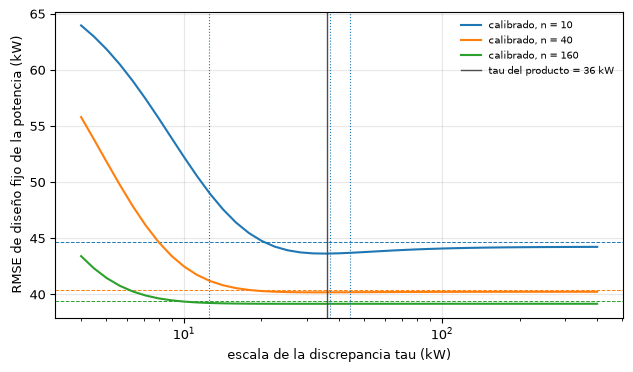

In [16]:
# Figura 4: el RMSE de diseño fijo del predictor calibrado frente a la escala de la discrepancia tau, con los
# óptimos por dirección |delta_k| de los diez muestreos marcados
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for n, color in zip(tau_rmse, ("C0", "C1", "C2")):
    ax.plot(taus, tau_rmse[n], color=color, label=f"calibrado, n = {n}")
    ax.axhline(tau_ls[n], color=color, lw=0.7, ls="--")
for d in tau_delta[10]:
    ax.axvline(d, color="C0", lw=0.8, ls=":")
ax.axvline(cb.DISCREPANCY_SD["kW"], color="0.3", lw=1.0, label="tau del producto = 36 kW")
ax.set_xscale("log")
ax.set_xlabel("escala de la discrepancia tau (kW)")
ax.set_ylabel("RMSE de diseño fijo de la potencia (kW)")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

La escala del producto queda en el fondo de un valle plano. Bajo el menor desajuste, 12,6 kW, el costo es empinado, porque el a priori prohíbe entonces el plano que los datos necesitan. Hacia $\tau$ grande el predictor tiende a mínimos cuadrados más el desvío $e_h$ del motor (la forma de cresta (3) con $\lambda = 0$), así que cada curva queda bajo su recta discontinua de mínimos cuadrados por la ganancia de curvatura en vez de alcanzarla. Estos son los óptimos de diseño fijo de (10), calculados en los puntos de entrenamiento; en puntos retenidos entra el término cruzado de (8) y el óptimo se mueve, lo que la celda siguiente lee del estudio versionado. La discrepancia ortogonal de Plumlee (2017) y el a priori escalado de Gu y Wang (2018) cambian este cuadro solo a través de la penalización. El a priori escalado contrae más en las direcciones que el diseño mide mejor, las de $g_k$ grande, lo opuesto de lo que pide (10) cuando esas direcciones llevan los desajustes grandes, y en el límite difuso el a priori ortogonal deja las predicciones sin cambio y solo cambia lo que significan los escalares.

El óptimo de diseño fijo de arriba responde dónde (10) pone la escala en los puntos de entrenamiento. El estudio versionado también calcula el riesgo en puntos retenidos, sobre 400 diseños aleatorios por tamaño, en la planta ajustada a los diez muestreos. Para diez y 160 muestreos registra el mejor $\tau$, el RMSE del predictor calibrado en el mejor y con los 36 kW del producto, y el RMSE de mínimos cuadrados y de la recta de la abertura. La celda los lee e imprime las diferencias que deciden el orden de los métodos.

In [17]:
# El riesgo con retención frente a tau sobre 400 diseños aleatorios, leído del estudio versionado: la mejor escala
# y las brechas que ordenan el predictor calibrado, mínimos cuadrados y la recta de la abertura
held_out = tau_cov["tau"]["by_n"]
print("n  mejor tau  RMSE mejor  RMSE con 36  RMSE MCO  RMSE recta  36 menos mejor  36 menos recta  "
      "mejor menos recta  desajustes")
for n in ("10", "160"):
    row = held_out[n]
    at_36, best, line = row["rmse_cb_at_product_tau"], row["rmse_cb_best"], row["rmse_line"]
    values = (best, at_36, row["rmse_ls"], line, at_36 - best, at_36 - line, best - line)
    mismatch = " ".join(f"{v:.1f}" for v in sorted(row["abs_delta_k"]))
    print(f"{n:>3s} {row['tau_best']:9.1f} " + " ".join(f"{v:10.3f}" for v in values) + "   " + mismatch)

n  mejor tau  RMSE mejor  RMSE con 36  RMSE MCO  RMSE recta  36 menos mejor  36 menos recta  mejor menos recta  desajustes
 10      25.2     44.873     45.144     46.767     45.068      0.271      0.076     -0.195   10.0 29.5 37.2
160      28.3     39.174     39.175     39.441     40.607      0.001     -1.432     -1.433   10.0 29.5 37.2


En puntos retenidos sobre diseños aleatorios la mejor escala es 25,2 kW con diez muestreos y 28,3 kW con 160, con desajustes de 10,0, 29,5 y 37,2 kW frente a los 12,6, 36,7 y 44,0 kW del diseño propio de los diez muestreos: dos óptimos para dos preguntas, el de diseño fijo en los puntos de entrenamiento, 35,65 kW, y el de retención, 25,2 kW, en el mismo valle plano. Con diez muestreos los 36 kW del producto cuestan 0,271 kW de RMSE frente al mejor, y ese es todo el tramo en que se decide el orden frente a la recta: con 36 kW el predictor calibrado queda 0,076 kW detrás de la recta y con la mejor escala 0,195 kW delante (las dos últimas columnas de diferencias, la segunda con signo frente a la recta). Una diferencia de 0,2 kW queda muy por debajo de lo que pueden mostrar diez muestreos con un ruido de 38,812 kW, así que con diez muestreos la escala no separa al método de la recta, y el ruido sí. Frente a mínimos cuadrados el método gana con toda escala del valle. Con 160 muestreos el predictor calibrado queda 1,432 kW delante de la recta tanto con 36 kW como con la mejor escala.

### El techo de información de la base de capacidad

Una pregunta distinta: no qué tan bien predice el predictor, sino qué pueden enseñar los muestreos sobre los escalares. Para la base de capacidad $Q_{\mathrm{ref}}$ la sensibilidad del tonelaje a $\ln Q_{\mathrm{ref}}$ es el tonelaje mismo, afín en la abertura y por tanto en el espacio de los regresores de la discrepancia: $\mathbf j = \mathbf Z\mathbf c$. Cualquier cambio de $\ln Q_{\mathrm{ref}}$ puede entonces ser absorbido por la discrepancia del tonelaje. La información de Fisher de la verosimilitud marginal, con la discrepancia integrada, es

$$\mathcal I(\ln Q_{\mathrm{ref}}) = \mathbf c^{\top}\mathbf G\bigl(\sigma^2\mathbf I + \tau^2\mathbf G\bigr)^{-1}\mathbf c \;\le\; \frac{\lVert\mathbf c\rVert^2}{\tau^2} \tag{11}$$

para todo diseño y todo número de muestreos, porque cada valor propio $g/(\sigma^2 + \tau^2 g)$ es menor que $1/\tau^2$: muestreos en el mismo rango de abertura no pueden llevar la información más allá del techo. La potencia informa solo el producto de la base de capacidad, el índice de trabajo y la pendiente de potencia, una confusión estructural del motor, así que la desviación estándar a posteriori de $\ln Q_{\mathrm{ref}}$ sobre la a priori tiene un piso en el modelo gaussiano linealizado para muestreos a velocidad fija en el mismo rango de abertura,

$$\frac{\mathrm{sd}(\ln Q_{\mathrm{ref}}\mid\mathcal D)}{s_Q} \;\ge\; \Bigl(1 + s_Q^2\,\frac{\lVert\mathbf c\rVert^2}{\tau^2} + \frac{s_Q^2}{s_W^2 + s_\zeta^2}\Bigr)^{-1/2} \tag{12}$$

con $s_Q$, $s_W$ y $s_\zeta$ las desviaciones estándar a priori de los logaritmos de la base de capacidad, el índice de trabajo y la pendiente de potencia. La celda recalcula (11) y (12), y la razón con solo tonelaje $(1 + s_Q^2\mathcal I)^{-1/2}$, desde los diez muestreos con el motor en los escalares ajustados, tomando la sensibilidad por diferencias centrales del motor en $\ln Q_{\mathrm{ref}}$, y los pone junto a los valores versionados del estudio.

In [18]:
# La información de los diez muestreos sobre ln Q_ref desde el tonelaje, con la discrepancia integrada: la
# sensibilidad es el tonelaje mismo del motor y está en el espacio de los regresores
step = 1e-4
up, down = fit.theta0.copy(), fit.theta0.copy()
up[0] += step
down[0] -= step
ups = [evaluate(op, cb.scalars_of(np.concatenate([up, [0.0, 0.0]]))).throughput_tph for op in problem.ops]
downs = [evaluate(op, cb.scalars_of(np.concatenate([down, [0.0, 0.0]]))).throughput_tph for op in problem.ops]
sens = (np.array(ups) - np.array(downs)) / (2 * step)
coef = np.linalg.lstsq(Z10, sens, rcond=None)[0]
out_of_span = np.linalg.norm(sens - Z10 @ coef) / np.linalg.norm(sens)
sig_t, tau_t = fit.sigma["tph"], cb.DISCREPANCY_SD["tph"]
G10 = Z10.T @ Z10
# Ecuación (11): la información y el techo que nunca puede pasar
info = coef @ G10 @ np.linalg.solve(sig_t**2 * np.eye(3) + tau_t**2 * G10, coef)
ceiling = coef @ coef / tau_t**2
prior_sd = {p.name: p.sd for p in cb.PRIORS}
s_q, s_w, s_z = prior_sd["q_ref_tph"], prior_sd["wi_kwh_t"], prior_sd["zeta"]
# Ecuación (12): el piso de la contracción de ln Q_ref con muestreos a esta velocidad en el mismo rango de abertura,
# y la razón con solo tonelaje
floor = (1 + s_q**2 * ceiling + s_q**2 / (s_w**2 + s_z**2)) ** -0.5
tph_only = (1 + s_q**2 * info) ** -0.5
shown = ident["ten_surveys"]
print("cantidad  calculada aquí  resumen versionado")
print(f"información desde el tonelaje  {info:9.3f}  {shown['tph_lnq_info_exact']:9.3f}")
print(f"techo |c|^2 / tau^2  {ceiling:9.3f}  {shown['tph_lnq_ceiling']:9.3f}")
print(f"razón de sd solo con tonelaje  {tph_only:9.4f}  {shown['tph_only_ratio_lnq']:9.4f}")
print(f"piso, velocidad fija, mismas aberturas  {floor:9.4f}  {shown['floor_ratio_lnq_any_n_fixed_speed']:9.4f}")
print("sensibilidad fuera del espacio de los regresores, relativa: bajo 1e-9 es {}".format(out_of_span < 1e-9))
print("modelo linealizado con ambas salidas {:.4f} | muestreador en los diez muestreos {:.4f}".format(
    shown["linearized_ratio"]["q_ref_tph"], shown["measured_ratio_sampled_scale"]["q_ref_tph"]))

cantidad  calculada aquí  resumen versionado
información desde el tonelaje     54.878     54.878
techo |c|^2 / tau^2     60.792     60.792
razón de sd solo con tonelaje     0.4751     0.4751
piso, velocidad fija, mismas aberturas     0.4240     0.4240
sensibilidad fuera del espacio de los regresores, relativa: bajo 1e-9 es True
modelo linealizado con ambas salidas 0.4570 | muestreador en los diez muestreos 0.4688


Las cantidades recalculadas coinciden con las versionadas: la información del tonelaje es 54,878 frente a un techo de 60,792, la razón de desviaciones estándar con solo tonelaje es 0,4751 y el piso para cualquier número de muestreos a velocidad fija en el mismo rango de abertura es 0,4240. La sensibilidad queda fuera del espacio de los regresores por menos de 1e-9 en términos relativos, que es la condición de (11). Con ambas salidas en el modelo linealizado la razón es 0,4570, y el muestreador corrido en los diez muestreos midió 0,4688. Los diez muestreos ya contienen 54,878 de los 60,792 como máximo que el tonelaje puede dar jamás sobre la base de capacidad.

La figura tiene dos paneles del resumen de identificabilidad versionado. A la izquierda, la desviación estándar a posteriori sobre la a priori de $\ln Q_{\mathrm{ref}}$ frente al número de muestreos sacados de la ventana de los muestreos, con la velocidad fija y variada, el piso de (12) y el valor del muestreador con diez muestreos. A la derecha, los ocho escalares con diez muestreos, el modelo linealizado frente al muestreador.

velocidades del diseño variado (rpm): [324.0, 360.0, 396.0]
fixed_speed   n = 10: 0.4617   n = 640: 0.4399
varied_speed  n = 10: 0.4629   n = 640: 0.4405


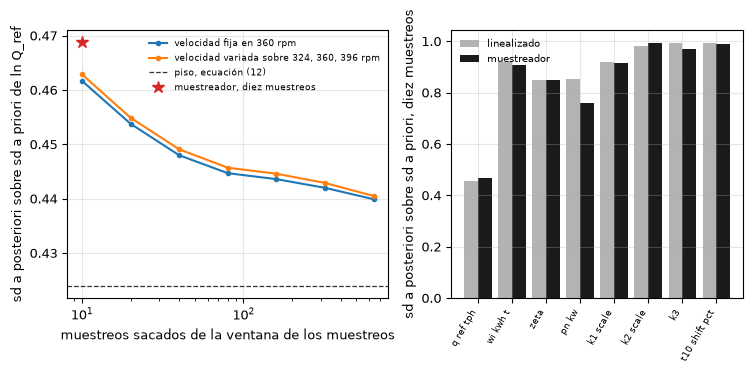

In [19]:
# Figura 5: la contracción de ln Q_ref frente al número de muestreos, velocidad fija y velocidad variada, con
# el piso y el valor del muestreador; y los ocho escalares con diez muestreos, linealizado frente a muestreado
fig, (left, right) = plt.subplots(1, 2, figsize=(7.6, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
sweep_n = ident["sweep"]["n"]
speeds = {"fixed_speed": "velocidad fija en 360 rpm",
          "varied_speed": "velocidad variada sobre 324, 360, 396 rpm"}
for key, label in speeds.items():
    left.plot(sweep_n, [ident["sweep"][key][str(n)]["q_ref_tph"] for n in sweep_n], marker="o", ms=3, label=label)
left.axhline(floor, color="0.2", ls="--", lw=0.9, label="piso, ecuación (12)")
measured = shown["measured_ratio_sampled_scale"]
left.plot([10], [measured["q_ref_tph"]], "*", color="C3", ms=9, label="muestreador, diez muestreos")
left.set_xscale("log")
left.set_xlabel("muestreos sacados de la ventana de los muestreos")
left.set_ylabel("sd a posteriori sobre sd a priori de ln Q_ref")
left.legend(frameon=False, fontsize=6.5)
print("velocidades del diseño variado (rpm): {}".format(ident["sweep"]["speeds_rpm"]))
for key in ("fixed_speed", "varied_speed"):
    first, last = (ident["sweep"][key][str(n)]["q_ref_tph"] for n in (sweep_n[0], sweep_n[-1]))
    print(f"{key:13s} n = {sweep_n[0]}: {first:.4f}   n = {sweep_n[-1]}: {last:.4f}")
names = list(shown["linearized_ratio"])
pos = np.arange(len(names))
right.bar(pos - 0.2, [shown["linearized_ratio"][k] for k in names], width=0.4, color="0.7", label="linealizado")
right.bar(pos + 0.2, [measured[k] for k in names], width=0.4, color="0.1", label="muestreador")
right.set_xticks(pos)
right.set_xticklabels([k.replace("_", " ") for k in names], rotation=60, ha="right", fontsize=6.5)
right.set_ylabel("sd a posteriori sobre sd a priori, diez muestreos")
right.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

El panel izquierdo es la saturación. De 10 a 640 muestreos la razón cae solo de 0,4617 a 0,4399 con velocidad fija, y de 0,4629 a 0,4405 con la velocidad variada sobre 324, 360 y 396 rpm, que se mantiene sobre el piso de 0,4240 y, con diez muestreos, bajo el 0,4688 del muestreador. Variar la velocidad no rompe el techo porque la capacidad del motor es casi plana en torno a su velocidad óptima, así que la sensibilidad sacada del espacio de los regresores es una fracción pequeña del tonelaje. Más muestreos a la misma velocidad y en el mismo rango de abertura no son entonces una forma de aprender la base de capacidad, y el panel derecho muestra lo mismo: solo la base de capacidad se contrae a cerca de la mitad, mientras los demás escalares quedan entre 0,7608 y 0,9915 de su ancho a priori. El panel no muestra qué diseño ayudaría, lo que requiere otra salida medida; muestra que este no puede.

### Dónde falla el método: curvatura que no puede seguir, extrapolación y la linealización

La forma cerrada es exacta, y exactitud no es lo mismo que utilidad. Cuatro límites aparecen en los resúmenes versionados y en las celdas anteriores. Primero, una curvatura del motor excesiva o mal alineada: fuera de $0 < \kappa < 2\rho$ la ganancia de (7) es negativa, como mostraron las filas $\alpha = -1$ y el motor con exponentes a la mitad en la ventana ancha. Segundo, un motor afín: (8) deja solo una contracción que decae con $n$. Tercero, la extrapolación frente a una curvatura que el motor no modela. La planta V1(1, 2) agrega una curvatura $q$ en la abertura ortogonal a la propia del motor, $\langle e, q\rangle = 0$, así que por (7) entra en $r$ pero no en la ganancia, y en la ventana de entrenamiento la ganancia debería quedar donde estaba; fuera de la ventana, donde $q$ crece cuadráticamente, ninguna regresión de ninguna clase puede conocerla. Cuarto, la linealización: (11) y (12) son propiedades del modelo linealizado en los escalares, y el muestreador mide lo que la linealización deja fuera. La celda imprime los números versionados de cada uno, y pregunta al filtro de envolvente del propio motor cuánto de cada ventana queda fuera del soporte que el producto calibró.

In [20]:
# Dónde la forma cerrada deja de describir el método, desde los resúmenes versionados: curvatura que el motor
# no puede seguir, curvatura de forma equivocada y la linealización de los escalares
for kind in ("rocha", "rocha_half"):
    for design in ("surveys", "wide", "extrapolation"):
        s = ccap[(kind, design, 160)]["predictors_summary"]["tph"]
        ratio = s["cb_oracle"]["rmse"] / s["ls"]["rmse"]
        print(f"{kind:11s} {design:14s} n = 160  razón de RMSE, calibrado sobre MCO  {ratio:.4f}")
print(""
      "curvatura que el motor no puede seguir, V1(1, 2): ganancia pareada sobre MCO (kW^2) y cobertura de 80%")
gains = {}
for name in ("a1", "a1_k2"):
    for design in ("surveys", "extrapolation"):
        cell = v1_cells[(name, design)]
        gain = cell["paired"]["kW"]["cb_oracle"]["vs_ls"]
        cover = cell["predictors_summary"]["kW"]["cb_oracle"]["coverage80"]
        label = "V1(1, 2)" if name == "a1_k2" else "V1(1)"
        gains[(name, design)] = -gain["mean"]
        print(f"{label:9s} {design:14s} ganancia  {-gain['mean']:8.2f} +- {gain['mcse']:.2f}  cobertura  {cover:.3f}")
print("ventana de los muestreos, ganancia con la curvatura agregada menos sin ella: {:.2f}".format(
    gains[("a1_k2", "surveys")] - gains[("a1", "surveys")]))
# La parte de cada ventana que el filtro de envolvente del propio motor marca como fuera de su soporte calibrado
for window in ("surveys", "wide"):
    pts = pools.window_points(window, 300)
    codes = [k for c, f, _ in pts for k in check_envelope(operating_from_survey(c, f), f).codes]
    counts = {k: codes.count(k) for k in sorted(set(codes))}
    print("ventana", window, "códigos del filtro en 300 puntos", counts)
print("contracción linealizada frente a muestreada con diez muestreos (razón de sd a posteriori sobre a priori)")
for k in shown["linearized_ratio"]:
    lin, smp = shown["linearized_ratio"][k], shown["measured_ratio_sampled_scale"][k]
    print(f"{k:14s} linealizado  {lin:.4f}  muestreado  {smp:.4f}  brecha  {smp - lin:+.4f}")

rocha       surveys        n = 160  razón de RMSE, calibrado sobre MCO  0.9917
rocha       wide           n = 160  razón de RMSE, calibrado sobre MCO  0.9902
rocha       extrapolation  n = 160  razón de RMSE, calibrado sobre MCO  0.9777
rocha_half  surveys        n = 160  razón de RMSE, calibrado sobre MCO  0.9951
rocha_half  wide           n = 160  razón de RMSE, calibrado sobre MCO  1.0019
rocha_half  extrapolation  n = 160  razón de RMSE, calibrado sobre MCO  1.0049
curvatura que el motor no puede seguir, V1(1, 2): ganancia pareada sobre MCO (kW^2) y cobertura de 80%
V1(1)     surveys        ganancia     20.38 +- 0.60  cobertura  0.799
V1(1)     extrapolation  ganancia     55.79 +- 1.68  cobertura  0.801
V1(1, 2)  surveys        ganancia     22.08 +- 0.62  cobertura  0.788
V1(1, 2)  extrapolation  ganancia   -916.50 +- 3.26  cobertura  0.269
ventana de los muestreos, ganancia con la curvatura agregada menos sin ella: 1.70
ventana surveys códigos del filtro en 300 puntos {'f80_lt_css

Los dos primeros límites están en las filas de capacidad: el motor con exponentes a la mitad queda en 1,0019 en la ventana ancha y 1,0049 en extrapolación, una pérdida, y el motor afín en 0,9999 con 160 muestreos. Para el tercero, en la ventana de los muestreos la curvatura agregada deja la ganancia en 22,08 kW$^2$ frente a 20,38 sin ella, una diferencia de 1,70 kW$^2$ frente a errores estándar de Monte Carlo de 0,60 y 0,62 en las dos ganancias, o sea a unos dos errores estándar de la diferencia de sin cambio, como dice (7) salvo ruido de simulación. En extrapolación la ganancia cae de 55,79 a -916,50 kW$^2$ y la banda de 80 por ciento cubre 0,269 de los puntos de prueba en vez de 0,801: ningún predictor del estudio es confiable fuera de su ventana de entrenamiento frente a una curvatura que no modela. Para el cuarto, la contracción linealizada y la muestreada coinciden en 0,0005 para zeta, 0,0002 para la escala de $K_1$ y 0,0126 para el índice de trabajo, pero la potencia en vacío es 0,8525 linealizada frente a 0,7608 muestreada, una brecha de -0,0917, y $K_3$ es 0,9941 frente a 0,9704: el muestreador contrae estos dos escalares más que el modelo linealizado. El motor es afín en la potencia en vacío, cuya sensibilidad es 1 en cada punto de operación, así que la no linealidad en ese escalar no puede ser la causa. El estudio nombra como candidatos los a priori truncados que el modelo linealizado omite, la escala de ruido que aprende el muestreador y la linealización en el centro del a priori, y este notebook no decide entre ellos, así que el muestreador sigue siendo la referencia. El filtro de envolvente del propio motor coincide con el régimen de extrapolación: entre 300 puntos de la ventana de los muestreos marca 5 cuya alimentación es más fina que la abertura (`f80_lt_css`) y ninguno fuera del soporte calibrado, mientras que en la ventana ancha marca 182 por la abertura y 7 por el tamaño de alimentación, así que los casos donde el predictor falla son los que el producto ya marca como fuera de su calibración.

### Úsalo con tus propios datos

Los diagnósticos necesitan una tabla de muestreos con la abertura, el tamaño de alimentación y las salidas medidas, como en el contrato `hp500-survey`, y los valores del motor con los escalares que vas a usar. Los pasos, aplicados abajo a la potencia de los diez muestreos como si fueran tu tabla:

1. Calcula $\mathbf e$ y $\hat{\mathbf r}$ con (4). Si $\mathbf e$ es menor que cerca de 1e-9 del nivel del motor, como lo fue el tonelaje, el motor es afín en tus regresores, y el método es una cresta hacia su plano sin ganancia persistente.
2. Estima la ganancia de curvatura con $\hat C = \frac1n\sum_i e_i(2\hat r_i - e_i)$. Como $\mathbf e$ es ortogonal a los regresores, $\mathbf e^{\top}\hat{\mathbf r} = \mathbf e^{\top}(\mathbf r + \boldsymbol\varepsilon)$ y el estimador es insesgado, con error estándar $2\hat\sigma\lVert\mathbf e\rVert/n$ y $\hat\sigma^2 = \lVert\hat{\mathbf r}\rVert^2/(n - 3)$, que incluye la curvatura propia de la planta y por eso es una estimación por exceso. Un puntaje $z$ cercano a cero significa que la tabla no puede decidir.
3. Pon un intervalo de Fisher-$z$ a la correlación $\hat\rho$ de $\mathbf e$ y $\hat{\mathbf r}$, con $\sqrt{n - 3}$ en el denominador.
4. Elige $\tau$ con (10). Un plano ajustado es ruidoso, con $\mathbb E\,\hat\delta_k^2 = \delta_k^2 + \sigma^2/g_k$, así que la estimación por dirección es $\hat\tau_k = \sqrt{\max(\hat\delta_k^2 - \hat\sigma^2/g_k, 0)}$.

La celda hace los cuatro, con los escalares ajustados y con los de fábrica.

In [21]:
# El diagnóstico sobre una tabla propia, aquí los diez muestreos: el desvío e del motor y el residuo medido
# r-hat de la potencia, la ganancia de curvatura que implica con su error estándar y la escala que los datos
# permiten para tau
print(""
      "escalares  e rms  C-gorro  ee(C-gorro)  z  rho-gorro  intervalo 95% de rho  sigma-gorro  tau-gorro por dir.")
for label, pair in engine_at.items():
    f = pair[1]
    e, r_hat = plane[(label, "kW")]
    sigma_hat = math.sqrt(np.sum(r_hat**2) / 7)
    # C-gorro = media de e(2 r-gorro - e) es insesgado para C porque e es ortogonal a los regresores; su error
    # estándar es 2 sigma |e| / n
    c_hat = np.mean(e * (2 * r_hat - e))
    se = 2 * sigma_hat * np.linalg.norm(e) / 10
    rho_hat = np.corrcoef(e, r_hat)[0, 1]
    z_fisher = math.atanh(rho_hat)
    lo, hi = math.tanh(z_fisher - 1.96 / math.sqrt(7)), math.tanh(z_fisher + 1.96 / math.sqrt(7))
    # El desajuste de planos en las direcciones propias de G, menos la varianza del plano ajustado (sigma^2 /
    # g_k)
    g, V = np.linalg.eigh(Z10.T @ Z10)
    delta = V.T @ (np.linalg.lstsq(Z10, f, rcond=None)[0] - np.linalg.lstsq(Z10, y["kW"], rcond=None)[0])
    tau_hat = np.sqrt(np.maximum(delta**2 - sigma_hat**2 / g, 0.0))
    e_rms = np.sqrt(np.mean(e**2))
    print(f"{label:8s} {e_rms:7.2f} {c_hat:7.1f} {se:9.1f} {c_hat / se:5.2f} {rho_hat:8.3f} [{lo:6.2f}, {hi:5.2f}] "
          f"{sigma_hat:10.2f} {tau_hat.round(1)}")

escalares  e rms  C-gorro  ee(C-gorro)  z  rho-gorro  intervalo 95% de rho  sigma-gorro  tau-gorro por dir.
fitted      6.13   150.8     153.8  0.98    0.463 [ -0.24,  0.85]      39.66 [49.8 13.5 36.6]
shipped     5.63   136.4     141.3  0.97    0.450 [ -0.25,  0.84]      39.66 [ 46.8 112.4  40.3]


Con los escalares ajustados la estimación de la ganancia de curvatura es 150,8 kW$^2$ con un error estándar de 153,8, un $z$ de 0,98, y la correlación 0,463 tiene un intervalo de 95 por ciento de -0,24 a 0,85; con los escalares de fábrica la estimación es 136,4 con 141,3 (un $z$ de 0,97). El residuo medido puede entonces decir que la curvatura del motor está plausiblemente alineada con la de la planta, y no puede excluir una ganancia nula o negativa, porque el ruido, $\hat\sigma$ = 39,66 kW, es grande frente al desvío del motor de 6,13 kW; por eso la comparación con retención del notebook 03 no pudo separar a CrusherBayes de la recta. Sí puede decir que el motor de tonelaje es afín. Para $\tau$, las estimaciones por dirección con los escalares ajustados son 49,8, 13,5 y 36,6 kW, alrededor de los 36 kW del producto; con los de fábrica son 46,8, 112,4 y 40,3, porque el plano del motor de fábrica está lejos del plano de los datos en una dirección, un desajuste que los escalares absorben una vez aprendidos. Donde las estimaciones discrepan, elige por exceso: el valle de la curva de riesgo es plano sobre el menor desajuste y empinado bajo él.

## Resultados

**Respuesta:** Solo a través de la parte de su salida que no es un plano. CrusherBayes con sus escalares dados supera a mínimos cuadrados sobre los mismos regresores si y solo si el desvío del motor respecto de un plano tiene el signo de la planta y no es más del doble de su tamaño, $0 < \kappa < 2\rho$, y en las plantas del estudio la ganancia es $(2\alpha - 1)$ veces 17,605 kW$^2$, con cruce por cero en $\alpha = 0,5$; un Monte Carlo de 400 réplicas lo confirma, 0,292 kW$^2$ con un semiancho de 2,839 frente al 0,479 exacto en el cruce. El tonelaje del carril HP500 es afín en la abertura con cualquier valor de los escalares, así que su desvío respecto de un plano es menor que 1e-9 de su nivel y el método solo puede contraer hacia el plano del motor allí (una razón de 0,9999 frente a mínimos cuadrados con 160 muestreos), mientras que un motor de la forma propia de la planta gana 0,9917 en la ventana de los muestreos y 0,9777 en extrapolación. En la potencia el motor se desvía de un plano en 6,132 kW frente a un residuo medido de 33,182 kW y un ruido de 38,812 kW, así que con los diez muestreos los datos no pueden decidir el signo de la ganancia, con una estimación de 150,8 kW$^2$ y un error estándar de 153,8. La escala de la discrepancia no separa al método de la recta con diez muestreos: el óptimo de diseño fijo en el diseño de los diez muestreos es 35,65 kW y el óptimo con retención del estudio versionado es 25,2 kW, los 36 kW del producto están en el valle plano de ambos, y la escala decide el orden frente a la recta por 0,271 kW, muy por debajo de lo que pueden mostrar diez muestreos con un ruido de 38,812 kW. Lo que más muestreos a esta velocidad en el mismo rango de abertura no pueden cambiar nunca es la base de capacidad, cuya información está acotada en 60,792 y cuya contracción no puede bajar de 0,4240, frente a 0,4688 medido.

## Resumen

El notebook tomó a CrusherBayes con sus escalares fijos, el caso en que su predictivo es una regresión de cresta hacia el plano del motor más el desvío del motor respecto de ese plano, y midió cuándo ese desvío paga. El riesgo exacto, confirmado por una simulación en una planta virtual, dice que la curvatura del motor gana sobre una regresión con los mismos regresores solo cuando está alineada con la de la planta y no es más del doble de grande, gana $(2\alpha - 1)$ veces 17,605 kW$^2$ a lo largo de la familia de plantas y no se reduce con el número de muestreos. El tonelaje de HP500 es afín en la abertura, así que para él el método es solo una contracción que decae, y un motor de la forma curva correcta sería lo que lo haría pagar. La escala de la discrepancia del producto está en un valle plano, 36 kW frente a un óptimo de diseño fijo de 35,65 kW y un óptimo con retención de 25,2 kW, y decide el orden frente a la recta por 0,271 kW con diez muestreos. Los diez muestreos no pueden decir de qué lado de un medio está la planta, porque los 6,132 kW de curvatura del motor son pequeños junto a un ruido de 38,812 kW, y dejan la base de capacidad en 0,4688 de su ancho a priori donde ningún número de muestreos a esta velocidad en el mismo rango de abertura puede pasar de 0,4240.

El método falla donde la curvatura no coincide, donde se le pide extrapolar contra una curvatura que no modela, con una cobertura de 0,269 en el estudio, y donde la contracción linealizada de un escalar difiere de la muestreada, en 0,0917 para la potencia en vacío, una brecha que el notebook no atribuye. En una tabla propia los resultados útiles son el desvío del motor, el error estándar de la ganancia de curvatura y una estimación por dirección de la escala de la discrepancia.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- Plumlee, M. (2017), Bayesian calibration of inexact computer models, Journal of the American Statistical Association 112(519), 1274-1285. https://doi.org/10.1080/01621459.2016.1211016
- Tuo, R., Wu, C. F. J. (2015), Efficient calibration for imperfect computer models, The Annals of Statistics 43(6), 2331-2352. https://doi.org/10.1214/15-AOS1314
- Gu, M., Wang, L. (2018), Scaled Gaussian stochastic process for computer model calibration and prediction, SIAM/ASA Journal on Uncertainty Quantification 6(4), 1555-1583. https://doi.org/10.1137/17M1159890